In [38]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.append(str(root))

%load_ext autoreload
%autoreload 2

# https://github.com/jldbc/pybaseball

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:
import warnings

import numpy as np
import pandas as pd
import pybaseball.team_results as team_results

def make_numeric_compat(data):
    data = data.copy()
    if 'Attendance' in data.columns and data['Attendance'].count() > 0:
        data['Attendance'] = data['Attendance'].astype(str).str.replace(',', '', regex=False)
        data['Attendance'] = pd.to_numeric(data['Attendance'].replace(r'^Unknown$|^None$', np.nan, regex=True), errors='coerce')
    elif 'Attendance' in data.columns:
        data['Attendance'] = np.nan

    num_cols = ['R', 'RA', 'Inn', 'Rank', 'Attendance']
    for col in num_cols:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors='coerce')
    return data

team_results.make_numeric = make_numeric_compat

_get_table = team_results.get_table

def get_table_compat(*args, **kwargs):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', category=pd.errors.ChainedAssignmentError)
        return _get_table(*args, **kwargs)

team_results.get_table = get_table_compat


In [40]:
from pybaseball import cache, schedule_and_record
from src.analysis import home_away_record

cache.enable()
oakland = schedule_and_record(2012, "OAK")
giants = schedule_and_record(2012, "SFG")
home_away_record(oakland)
home_away_record(giants)

Home_Away  W/L 
@          L       27
           L-wo     7
           W       46
Home       L       33
           W       41
           W-wo     7
dtype: int64

In [41]:
from src.analysis import win_pct_by_site

g = win_pct_by_site(giants)
g = g.rename(columns={"wins": "W", "games": "GMs", "win_pct": "Win%"})
g = g.round(2)


a = win_pct_by_site(oakland)
a = a.rename(columns={"wins": "W", "games": "GMs", "win_pct": "Win%"})
a = a.round(2)

print("Giants win % by site:\n", g)
print("\n")
print("Oakland win % by site:\n", a)

Giants win % by site:
        W  GMs  Win%
site               
Away  46   80  0.57
Home  48   81  0.59


Oakland win % by site:
        W  GMs  Win%
site               
Away  44   81  0.54
Home  49   80  0.61


In [42]:
from scipy.stats import fisher_exact

for label, df in [("Giants", g), ("Oakland", a)]:
    table = [
        [df.loc["Home", "W"], df.loc["Home", "GMs"] - df.loc["Home", "W"]],
        [df.loc["Away", "W"], df.loc["Away", "GMs"] - df.loc["Away", "W"]],
    ]

    odds_ratio, p_value = fisher_exact(table)
    print(f"{label}: odds ratio = {odds_ratio:.3f}, p-value = {p_value:.3f}\n")

Giants: odds ratio = 1.075, p-value = 0.874

Oakland: odds ratio = 1.329, p-value = 0.426



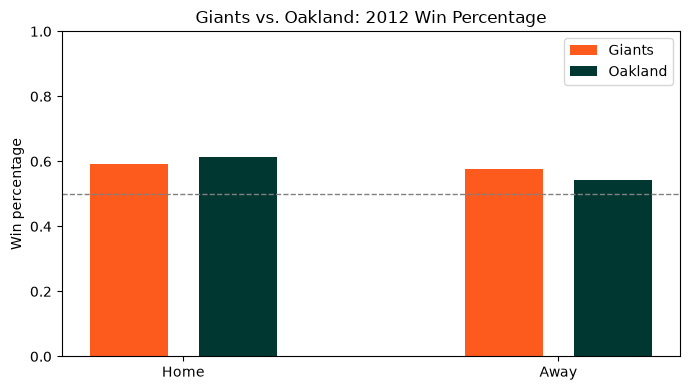

In [147]:
import matplotlib.pyplot as plt
import numpy as np

g_plot = win_pct_by_site(giants)
a_plot = win_pct_by_site(oakland)

sites = ["Home", "Away"]
x = np.arange(len(sites)) * 1.2
bar_width = 0.25
fig, ax = plt.subplots(figsize=(7, 4))
gap = 0.1
offset = (bar_width + gap) / 2

ax.bar(
    x - offset,
    g_plot.loc[sites, "win_pct"],
    bar_width,
    label="Giants",
    color="#FD5A1E",
)
ax.bar(
    x + offset,
    a_plot.loc[sites, "win_pct"],
    bar_width,
    label="Oakland",
    color="#003831",
)

ax.set_xticks(x, sites)
ax.set_ylim(0, 1)
ax.set_ylabel("Win percentage")
ax.set_title("Giants vs. Oakland: 2012 Win Percentage")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.legend()

fig.tight_layout()